In [248]:
import os

import pandas


RESULT_PATH_PREFIX = 'Sample_aris_df_threshold'


results_csv_paths = [
    subpath
    for subpath in os.listdir()
    if subpath.startswith(RESULT_PATH_PREFIX) and 'gpu' not in subpath and 'ds' not in subpath and '50' not in subpath and '200' not in subpath
]

results_csvs = [
    pandas.read_csv(subpath)
    for subpath in results_csv_paths
    if len(subpath.split('_')) == 7
]

In [249]:
for path, csv in zip(results_csv_paths, results_csvs):
    threshold = path.split('_')[4]
    run = path.split('_')[-1].split('.')[0]
    csv['threshold'] = float(threshold)
    csv['run'] = int(run)

In [250]:
total_result_csv = pandas.concat(results_csvs, ignore_index=True)

In [251]:
FULL_SAMPLE_COLS = ['151673', '151672', '151507', '151508', '151669', '151509', '151671',
       '151510', '151670', '151674', '151675', '151676']

TRAIN_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

TEST_SAMPLES = [col for col in FULL_SAMPLE_COLS if col not in TRAIN_SAMPLES]

In [252]:
total_result_csv['total_train'] = total_result_csv[TRAIN_SAMPLES].median(axis=1)
total_result_csv['total_test'] = total_result_csv[TEST_SAMPLES].median(axis=1)

In [253]:
total_result_csv.groupby('threshold').size()

threshold
2.0     200
3.0     200
4.0     200
5.0     200
6.0     200
7.0     200
8.0     200
9.0     200
10.0    200
dtype: int64

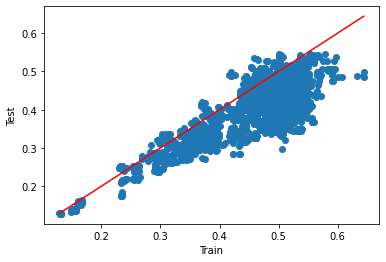

In [254]:
plt.scatter(
    total_result_csv['total_train'],
    total_result_csv['total_test'],
)
plt.xlabel('Train')
plt.ylabel('Test')

max_ = max(total_result_csv['total_train'].max(), total_result_csv['total_test'].max())
min_ = max(total_result_csv['total_train'].min(), total_result_csv['total_test'].min())

plt.plot([min_, max_], [min_, max_], c='r')

In [255]:
full_result_csv = total_result_csv.groupby(['run', 'threshold', 'PLDA'])[FULL_SAMPLE_COLS].mean().reset_index()

In [256]:
full_result_csv['total_test'] = full_result_csv[TEST_SAMPLES].median(axis=1)
full_result_csv['total_train'] = full_result_csv[TRAIN_SAMPLES].median(axis=1)

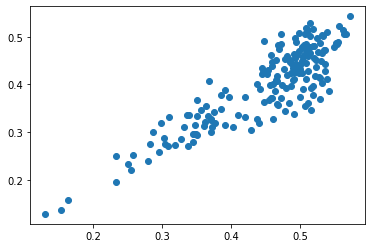

In [257]:
plt.scatter(
    full_result_csv['total_train'],
    full_result_csv['total_test']
)

In [258]:
total_result_csv['total_train'] = total_result_csv[TRAIN_SAMPLES].median(axis=1)

In [259]:
(total_result_csv['total_train'] <= 0.575).mean()

0.9866666666666667

In [260]:
(full_result_csv['total_train'] <= 0.575).mean()

1.0

In [261]:
full_result_csv = full_result_csv.groupby(['threshold', 'PLDA'])[['total_test', 'total_train']].max()

In [262]:
full_result_csv = full_result_csv.reset_index()

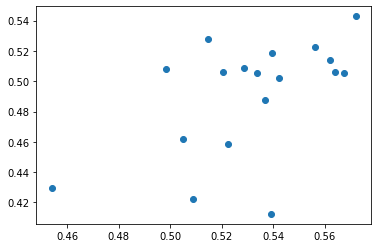

In [263]:
plt.scatter(
    full_result_csv['total_train'],
    full_result_csv['total_test']
)

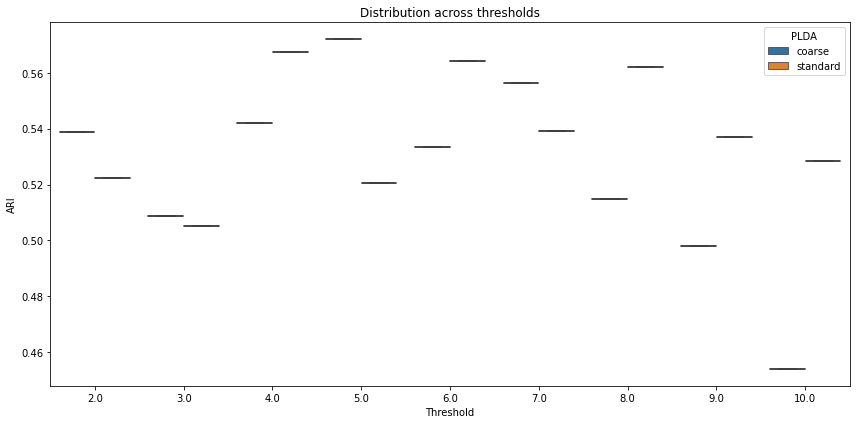

In [264]:
import matplotlib.pyplot as plt
import seaborn as sns





df_long = full_result_csv.melt(
    id_vars=["threshold", "PLDA"],
    value_vars=['total_train'],
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='PLDA')

plt.title("Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")

plt.tight_layout()
plt.show()

In [265]:
import matplotlib.pyplot as plt
import seaborn as sns


df_long = full_result_csv.melt(
    id_vars=["threshold", 'nb_of_standard_components'],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='nb_of_standard_components')

plt.title("Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0, 1])
plt.hlines(0.5, 0, 9)

plt.tight_layout()
plt.show()

KeyError: "The following 'id_vars' are not present in the DataFrame: ['nb_of_standard_components']"

In [266]:
import matplotlib.pyplot as plt
import seaborn as sns


df_long = full_result_csv.melt(
    id_vars=["threshold", 'nb_of_standard_components'],
    value_vars=FULL_SAMPLE_COLS,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='nb_of_standard_components')

plt.title("Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0, 1])
plt.hlines(0.5, 0, 9)

plt.tight_layout()
plt.show()

KeyError: "The following 'id_vars' are not present in the DataFrame: ['nb_of_standard_components']"

In [267]:
NON_TEST_SAMPLES = [sample for sample in FULL_SAMPLE_COLS if sample not in TEST_SAMPLES]

In [268]:
df_long_run_train = current_results.groupby(['threshold'])[NON_TEST_SAMPLES].mean().mean(axis=1).to_frame().reset_index()
df_long_run_test = current_results.groupby(['threshold'])[TEST_SAMPLES].mean().mean(axis=1).to_frame().reset_index()

KeyError: "Columns not found: '151672', '151507', '151673'"

In [269]:
df_long_run_train

NameError: name 'df_long_run_train' is not defined

In [270]:
plt.scatter(
    df_long_run_train[0], df_long_run_test[0], c=df_long_run_train['run'], cmap='coolwarm')

NameError: name 'df_long_run_train' is not defined

In [275]:
model_prefix = 'DLPFC_CELLOHOOD_MODEL'


model_paths = [
    path 
    for path in os.listdir()
    if path.startswith(model_prefix) and 'GPU' not in path and 'SPLIT' not in path and 'DS' not in path
]

In [276]:
histories = []


for path in model_paths:
    try:
        threshold = float(path.split('_')[3])
        run = int(path.split('_')[4])
        history_path = os.path.join(path, 'model_history.df')
        history = pandas.read_csv(history_path)
        history['threshold'] = threshold
        history['run'] = run
        histories.append(history)
    except IndexError:
        pass

In [277]:
histories_df = pandas.concat(histories, ignore_index=True)

In [278]:
histories_df_last = histories_df[histories_df['Unnamed: 0'] == 98]

In [279]:
histories_df_last = histories_df_last.sort_values(['threshold', 'run'])

In [280]:
grouped_results = full_result_csv.groupby(['threshold', 'run'])[TEST_SAMPLES].mean().reset_index()

KeyError: 'run'

In [281]:
total_with_loss = pandas.merge(grouped_results, histories_df_last)

NameError: name 'grouped_results' is not defined

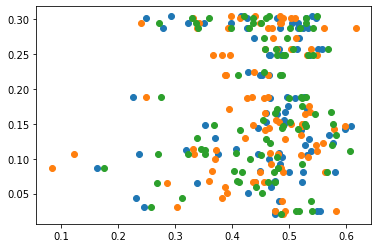

In [709]:
for sample in TEST_SAMPLES:
    plt.scatter(total_with_loss[sample], total_with_loss['loss'])